# Risk Management - Group Work Project 2: Hidden Markov Model Regimes in WTI Crude Oil and Bayesian Network Structure Learning

Note: the macro variables used in the Bayesian-network step are synthetic placeholders (simulated), used to demonstrate structure learning only.

In [ ]:
!pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 3.3 MB/s eta 0:00:00


In [ ]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 7.5 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


WTI sample:
                       Date      Price  LogReturn
0 2000-08-24 00:00:00-04:00  31.629999  -0.013191
1 2000-08-25 00:00:00-04:00  32.049999   0.013191
2 2000-08-28 00:00:00-04:00  32.869999   0.025263
3 2000-08-29 00:00:00-04:00  32.720001  -0.004574
4 2000-08-30 00:00:00-04:00  33.400002   0.020569


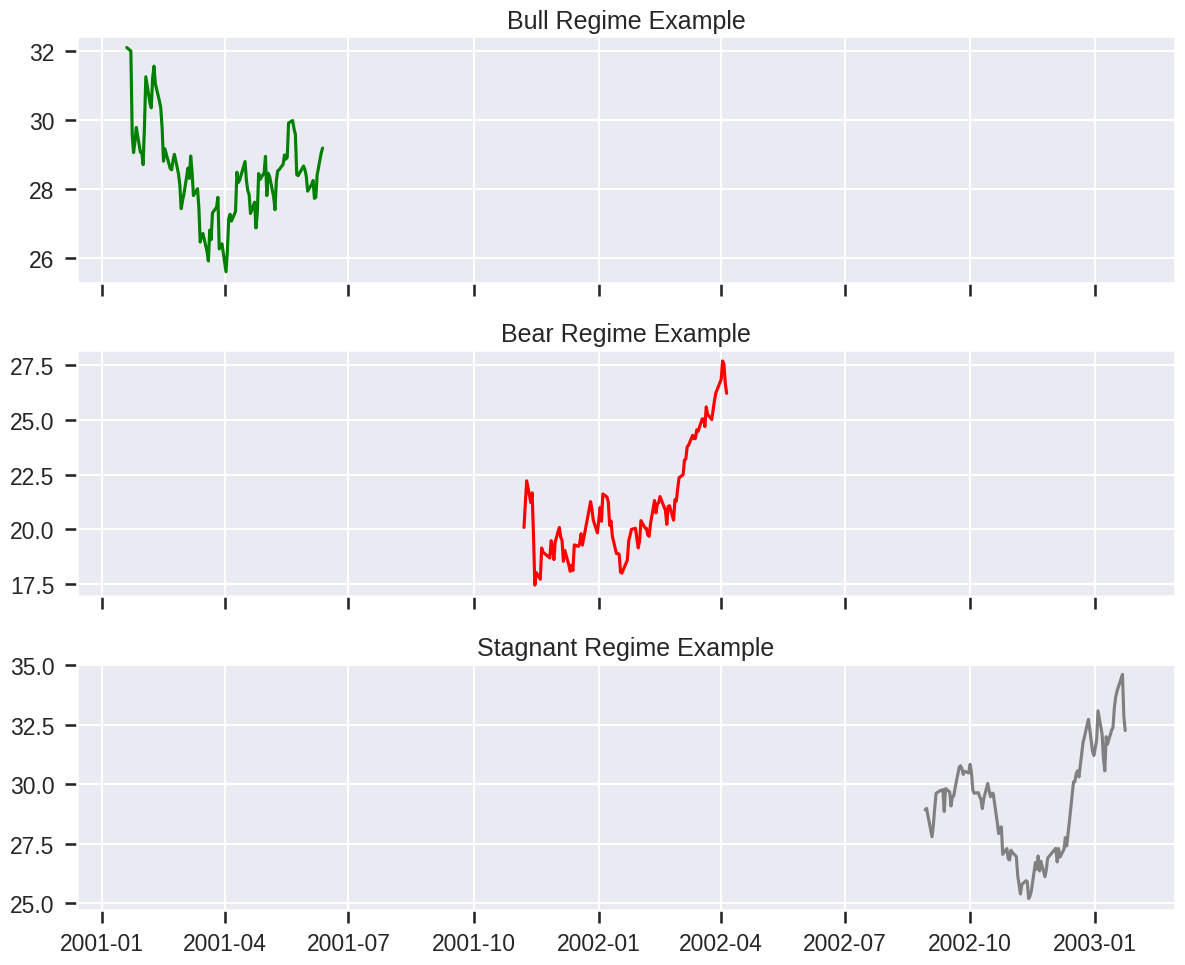

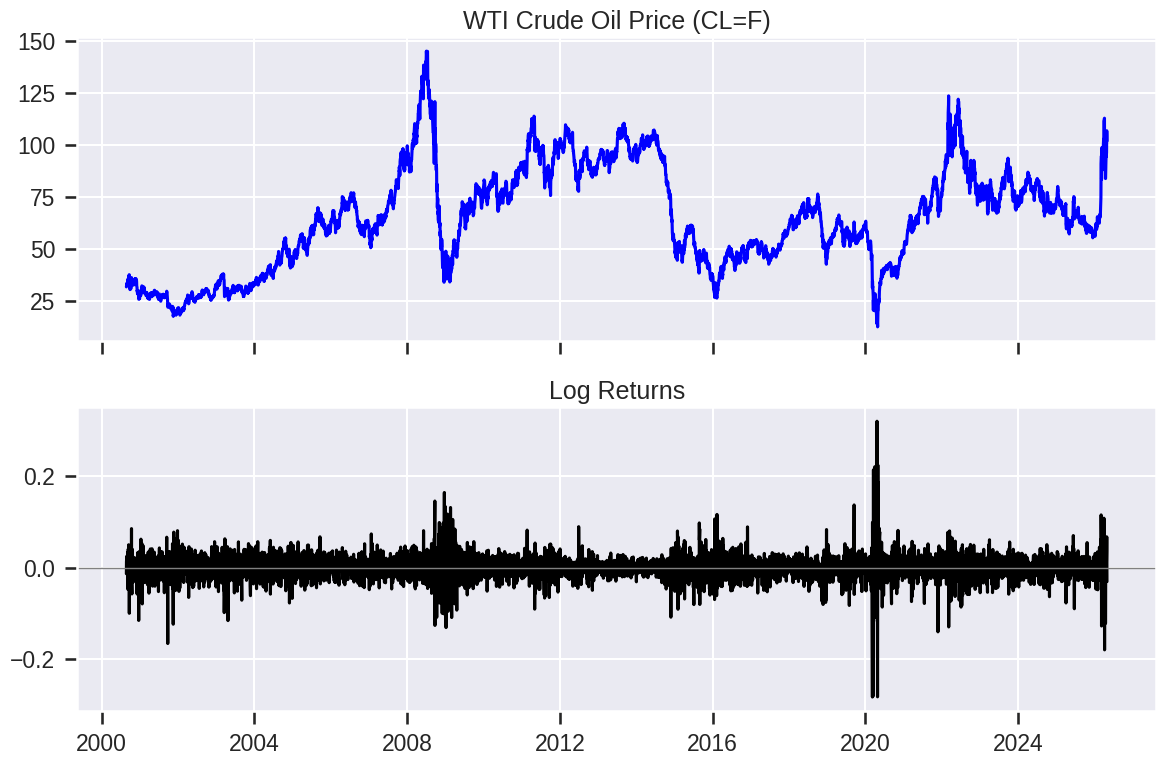

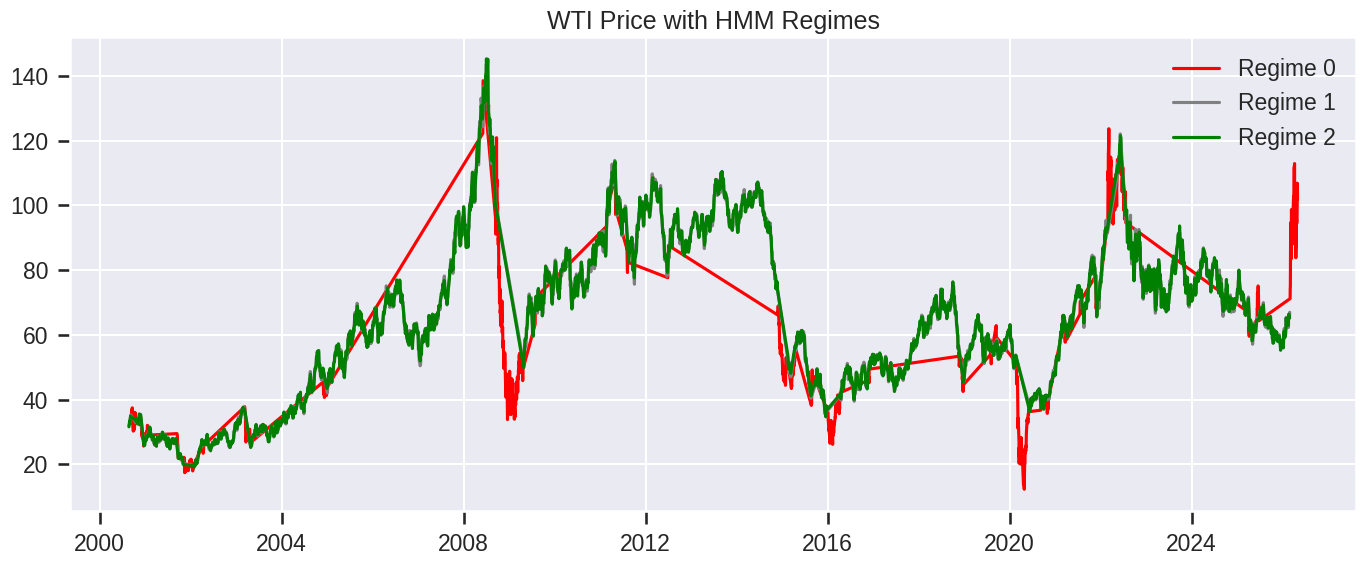

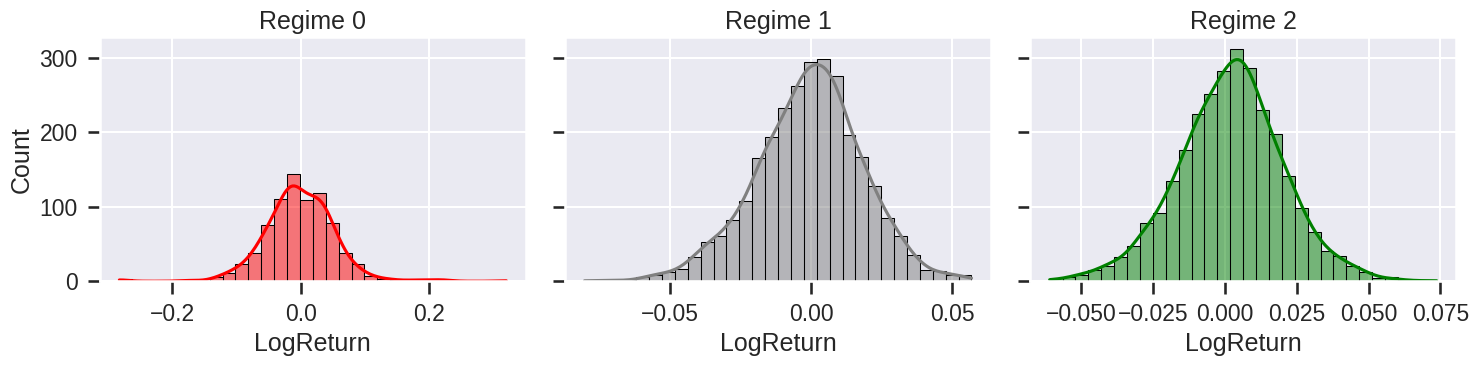

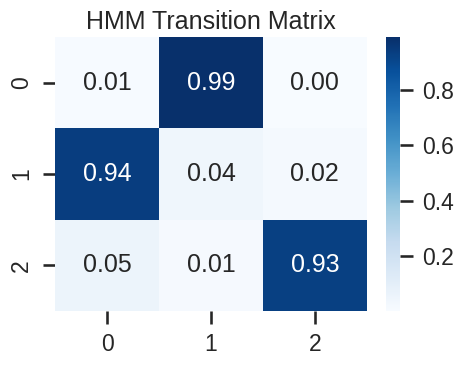

/tmp/ipykernel_2877/180818812.py:162: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(data_bn)


  0%|          | 0/1000000 [00:00<?, ?it/s]

Learned edges: [('IndustrialProduction', 'ExchangeRate'), ('Inventories', 'IndustrialProduction'), ('Inventories', 'ExchangeRate')]


/tmp/ipykernel_2877/180818812.py:176: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


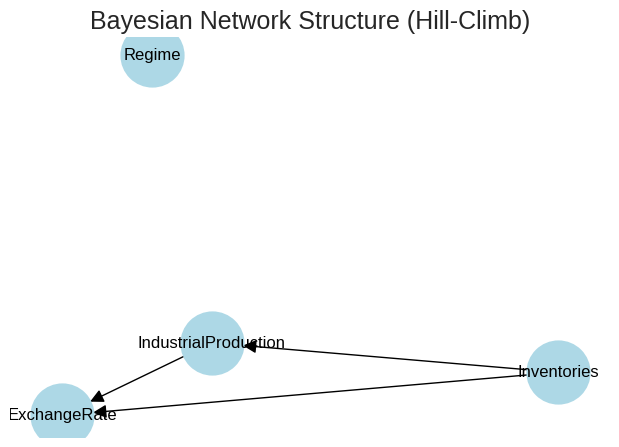

In [ ]:
# ============================================================
# GWP2 – Full Notebook: Steps 2–9 (WTI + HMM + BN + All Graphs)
# ============================================================

# ---------- 0. Install yfinance ----------
!pip install yfinance --quiet

# ---------- 1. Imports ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from hmmlearn.hmm import GaussianHMM
from pgmpy.estimators import HillClimbSearch
from pgmpy.models import BayesianNetwork
import networkx as nx

plt.style.use("seaborn-v0_8")
sns.set_context("talk")

# ============================================================
# 2. Download WTI (CL=F) using yfinance (never rate-limited)
# ============================================================

ticker = yf.Ticker("CL=F")
df = ticker.history(period="max")[["Close"]].reset_index()
df.rename(columns={"Close": "Price"}, inplace=True)

df = df.dropna().reset_index(drop=True)

# Log-returns
df["LogReturn"] = np.log(df["Price"]).diff()
df = df.dropna().reset_index(drop=True)

print("WTI sample:")
print(df.head())

# ============================================================
# 3. STEP 2 – Regime illustrations (bull, bear, stagnant)
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

bull_slice = df.iloc[100:200]
bear_slice = df.iloc[300:400]
stagnant_slice = df.iloc[500:600]

axes[0].plot(bull_slice["Date"], bull_slice["Price"], color="green")
axes[0].set_title("Bull Regime Example")

axes[1].plot(bear_slice["Date"], bear_slice["Price"], color="red")
axes[1].set_title("Bear Regime Example")

axes[2].plot(stagnant_slice["Date"], stagnant_slice["Price"], color="gray")
axes[2].set_title("Stagnant Regime Example")

plt.tight_layout()
plt.show()

# ============================================================
# 4. STEP 6.1 – Raw price vs log-returns
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(df["Date"], df["Price"], color="blue")
axes[0].set_title("WTI Crude Oil Price (CL=F)")

axes[1].plot(df["Date"], df["LogReturn"], color="black")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_title("Log Returns")

plt.tight_layout()
plt.show()

# ============================================================
# 5. STEP 6 – Fit HMM and get regimes
# ============================================================

X = df["LogReturn"].values.reshape(-1, 1)

hmm = GaussianHMM(
    n_components=3,
    covariance_type="full",
    n_iter=200,
    random_state=42
)
hmm.fit(X)

states = hmm.predict(X)
df["RegimeRaw"] = states

# Order regimes by mean return
state_means = pd.Series(
    [X[states == i].mean() for i in range(3)],
    index=range(3)
).sort_values()

mapping = {old: new for new, old in enumerate(state_means.index)}
df["Regime"] = df["RegimeRaw"].map(mapping)

colors = {0: "red", 1: "gray", 2: "green"}

# ============================================================
# 6. HMM regime plot
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for regime, group in df.groupby("Regime"):
    ax.plot(group["Date"], group["Price"],
            color=colors[regime], label=f"Regime {regime}")

ax.set_title("WTI Price with HMM Regimes")
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 7. Emission distributions
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for regime in [0, 1, 2]:
    sns.histplot(
        df.loc[df["Regime"] == regime, "LogReturn"],
        bins=30, kde=True, ax=axes[regime], color=colors[regime]
    )
    axes[regime].set_title(f"Regime {regime}")

plt.tight_layout()
plt.show()

# ============================================================
# 8. Transition matrix heatmap
# ============================================================

A = hmm.transmat_

plt.figure(figsize=(5, 4))
sns.heatmap(A, annot=True, fmt=".2f", cmap="Blues")
plt.title("HMM Transition Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# 9. STEP 9 – Bayesian Network (with synthetic macro variables)
# ============================================================

np.random.seed(42)

df["IndustrialProduction"] = 100 + 0.05*np.arange(len(df)) + np.random.normal(0, 1, len(df))
df["Inventories"] = 200 - 0.03*np.arange(len(df)) + np.random.normal(0, 2, len(df))
df["ExchangeRate"] = 1.3 + 0.0001*np.arange(len(df)) + np.random.normal(0, 0.01, len(df))

macro_cols = ["IndustrialProduction", "Inventories", "ExchangeRate"]
data_bn = df[macro_cols + ["Regime"]].dropna()

hc = HillClimbSearch(data_bn)
best_model = hc.estimate()  # no scoring class needed

print("Learned edges:", list(best_model.edges()))

# Plot DAG
G = nx.DiGraph()
G.add_nodes_from(best_model.nodes())
G.add_edges_from(best_model.edges())

plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=2000, node_color="lightblue", arrowsize=20)
plt.title("Bayesian Network Structure (Hill-Climb)")
plt.tight_layout()
plt.show()
